In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [52]:
import zipfile
from zipfile import ZipFile

In [53]:
#%pip install opencv-python

In [54]:
import cv2

In [55]:
os.listdir()

['cnn_binary_image.ipynb', 'model.png', '.ipynb_checkpoints']

In [56]:
os.getcwd()

'/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/notebooks'

In [57]:
data_dir = "/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/data"

os.listdir(data_dir)

['CATDOG', 'CATDOG.zip']

In [58]:
path = os.path.join(data_dir, 'CATDOG.zip')

In [59]:
#with zipfile.ZipFile(path, 'r') as data: #extracting the zip folder in the same path
 #   data.extractall(data_dir)
    

In [60]:
os.listdir(data_dir)

['CATDOG', 'CATDOG.zip']

In [61]:
#for root, dirs, files in os.walk(data_dir):
 #   print(root)
  ##  for file in files:
    #    print("   └──", file)

In [62]:
way = data_dir + '/CATDOG'

In [63]:
way

'/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/data/CATDOG'

In [64]:
os.listdir(way)

['training_set', 'test_set']

In [65]:
test_dir = way + '/test_set/'
train_dir = way + '/training_set/'

In [66]:
os.listdir(test_dir)

['dogs', 'cats']

In [67]:
os.listdir(train_dir)

['dogs', 'cats']

In [68]:
os.listdir(test_dir+'dogs')[0]

'dog.4159.jpg'

In [69]:
os.listdir(test_dir+'cats')[0]

'cat.4369.jpg'

In [70]:
os.listdir(train_dir+'dogs')[0]

'dog.1753.jpg'

In [71]:
mydog = test_dir+'dogs/'+os.listdir(test_dir+'dogs/')[7]
print(mydog)

/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/data/CATDOG/test_set/dogs/dog.4818.jpg


No Color Correction


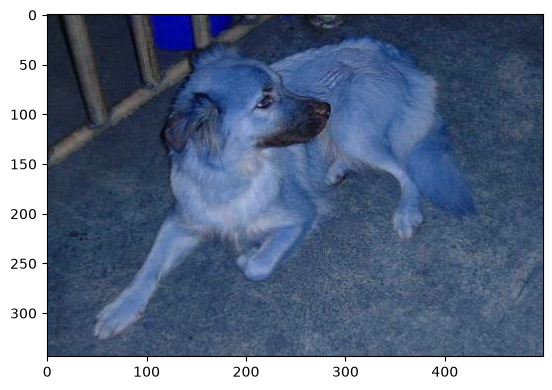

In [72]:
print('No Color Correction')
sample = cv2.imread(mydog)
plt.imshow(sample)


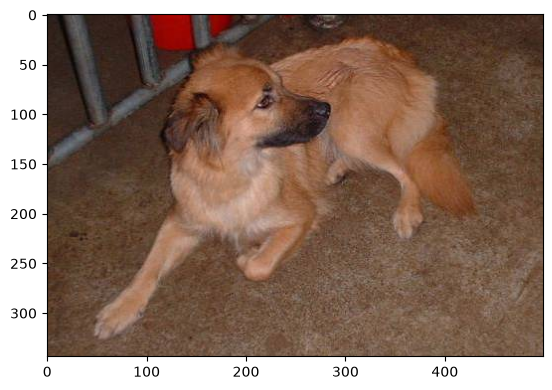

In [73]:
sample = cv2.imread(mydog)
sample = cv2.cvtColor(sample, cv2.COLOR_BGR2RGB)  #color correction
plt.imshow(sample) 

In [74]:
from matplotlib.image import imread #importing imread to replace cv2 for simplicity

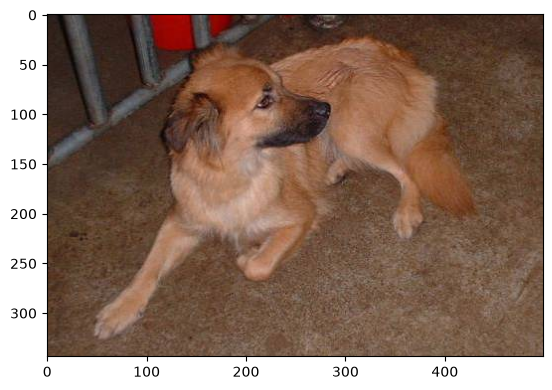

In [75]:
sample_matrix = imread(mydog)
plt.imshow(sample_matrix)   #unlike cv2, we do not have to color correct the images

In [76]:
sample_matrix.shape

(344, 499, 3)

In [77]:
test_dir +'dogs'

'/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/data/CATDOG/test_set/dogs'

In [78]:
shape_x = []                          #creating empty list for width of the images
shape_y = []                          #creating empty list for height of the images
color_channel = []                        #creating empty list for color channel of the images

for i in os.listdir(test_dir+'dogs'):     #running for loop in the dogs folder in test directory
  sample = imread(test_dir + 'dogs/'+i)   #selecting next image everytime    

  shape_x.append(sample.shape[0])               #adding widths in the list
  shape_y.append(sample.shape[1])               #adding hieght in the list
  color_channel.append(sample.shape[2])             #adding color channels in the list

In [79]:
min(shape_x), max(shape_x)

(33, 500)

In [80]:
min(shape_y), max(shape_y)

(92, 500)

In [81]:
min(color_channel), max(color_channel)

(3, 3)

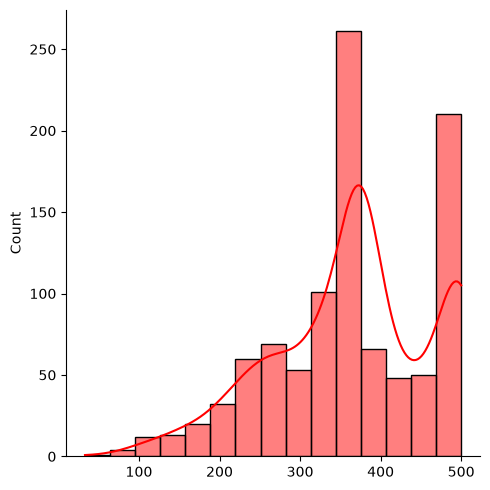

In [82]:
sns.displot(shape_x, bins=15, kde=True, color='red')

In [83]:
#importing other necessary libraries for sequential API model

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv2D, MaxPool2D, Flatten,BatchNormalization,MaxPooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [84]:
#%pip install tensorflow

In [85]:
#making instances of IDG for training and testing

train_IDG=ImageDataGenerator(#width_shift_range= 0.3,  #width manipulation
                         #height_shift_range=0.1,   #heigth manipulation
                         #rotation_range=40,       #rotation enable
                         rescale = 1/255,       #rescaling the images ****VVI****
                         #horizontal_flip =True,   #flipping horizontally able
                         #fill_mode= 'nearest'
                       )
test_IDG=ImageDataGenerator(#width_shift_range= 0.3,
                        #height_shift_range=0.1,
                        rotation_range=40,
                       rescale = 1/255,
                       #horizontal_flip =True,
                       #fill_mode= 'nearest'
                       )


    

In [86]:
imageshape = (100,100)    #defining size of image
batchsize = 100        #defining batch size


In [87]:
print('In the training direcotry, we')

train_generator = train_IDG.flow_from_directory(train_dir,
                                               target_size=imageshape,
                                               color_mode='rgb',
                                               batch_size=batchsize,
                                               class_mode='binary')
print()
print('In the testing direcotry, we')

validation_data_set = test_IDG.flow_from_directory(test_dir,
                                             target_size=imageshape,
                                             color_mode='rgb',
                                             batch_size=batchsize,
                                             class_mode='binary',
                                               shuffle=False)


In the training direcotry, we
Found 8020 images belonging to 2 classes.

In the testing direcotry, we
Found 2000 images belonging to 2 classes.


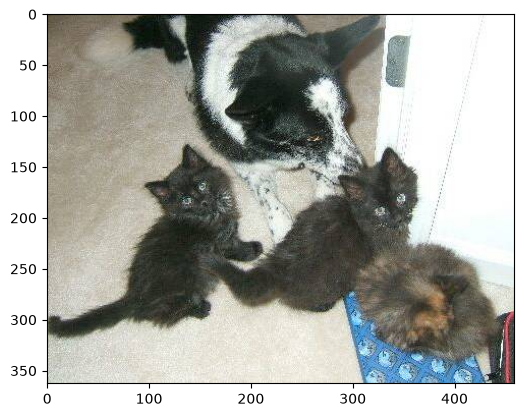

In [88]:
mycat = imread(test_dir+'/cats/cat.4104.jpg')  #reading the image from 'cats' folder and storing under my_cat
plt.imshow(mycat)        #visualising the image

These are some of the possible ways that IDG manipulates the images fed to the model


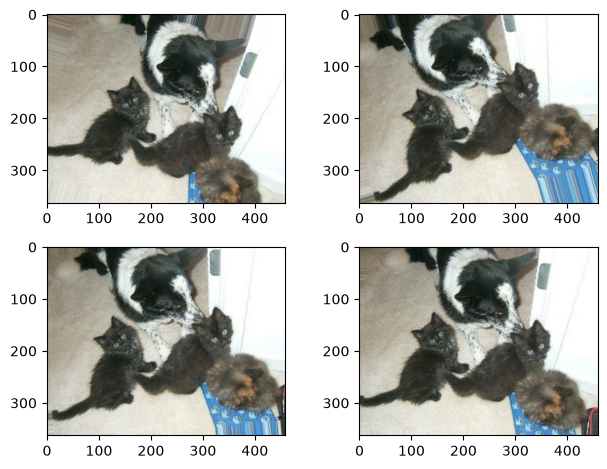

In [89]:
#visualizing what the instance made above does to the input image

fig, ax = plt.subplots(2,2)
plt.tight_layout()

#possibilities
ax[0][0].imshow(test_IDG.random_transform(mycat))
ax[0][1].imshow(test_IDG.random_transform(mycat))
ax[1][1].imshow(test_IDG.random_transform(mycat))
ax[1][0].imshow(test_IDG.random_transform(mycat))

print('These are some of the possible ways that IDG manipulates the images fed to the model')

In [90]:
mymodel = Sequential()

mymodel.add(Conv2D(32, kernel_size=(3,3),padding='valid', activation ='relu', input_shape=(100,100,3) ))
mymodel.add(BatchNormalization())
mymodel.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='valid'))

mymodel.add(Conv2D(64, kernel_size=(3,3), padding ='valid', activation ='relu', input_shape=(100,100,3)))
mymodel.add(BatchNormalization())
mymodel.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='valid'))

mymodel.add(Conv2D(64, kernel_size=(3,3), padding ='valid', activation ='relu', input_shape=(100,100,3)))
mymodel.add(BatchNormalization())
mymodel.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='valid'))

mymodel.add(Flatten())

mymodel.add(Dense(64, activation='relu'))
mymodel.add(Dropout(0.4))

mymodel.add(Dense(1, activation='sigmoid'))

mymodel.summary()


/opt/anaconda3/envs/cnn-env/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 98, 98, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 47, 47, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 21, 21, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 21, 21, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       409,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 466,689 (1.78 MB)

 Trainable params: 466,369 (1.78 MB)

 Non-trainable params: 320 (1.25 KB)

In [91]:
mymodel.compile(loss='binary_crossentropy',
                optimizer = 'adam',
                metrics=['accuracy'])


In [92]:
from tensorflow.keras.utils import plot_model

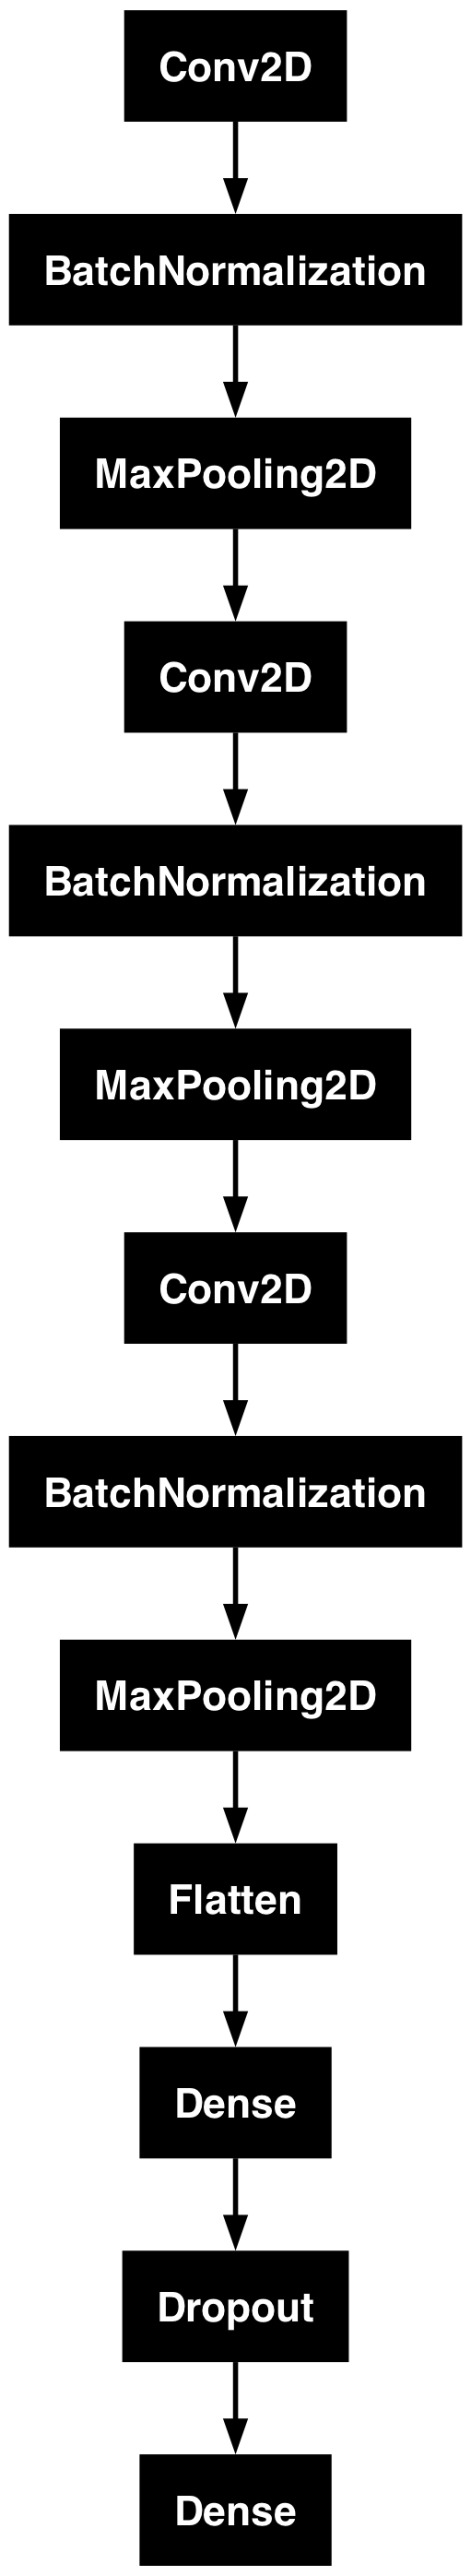

In [93]:

plot_model(mymodel)

In [94]:
#%pip install pydot

In [95]:
from tensorflow.keras.callbacks import EarlyStopping

In [96]:
es = EarlyStopping(monitor='val_loss', patience = 5)

In [97]:
train_generator.class_indices

{'cats': 0, 'dogs': 1}

In [98]:
validation_data_set.class_indices  #checking clas indices in test directory

{'cats': 0, 'dogs': 1}

In [108]:
#mymodelfit = mymodel.fit_generator(train_generator, 
#                                  epochs = 100,
#                                  validation_step = 100,
#                                  validation_data = validation_data_set,
 #                                 verbose = 1,
  #                                callbacks =[es])

In [111]:
#new models works with fit() rather than fit_generator()

mymodelfit = mymodel.fit(train_generator, 
                                  epochs = 100,
                                  #validation_steps = 100,
                                  validation_data = validation_data_set,
                                  verbose = 1,
                                  callbacks =[es])

Epoch 1/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 20s 243ms/step - accuracy: 0.8615 - loss: 0.3135 - val_accuracy: 0.6740 - val_loss: 0.8648
Epoch 2/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 235ms/step - accuracy: 0.8828 - loss: 0.2705 - val_accuracy: 0.6180 - val_loss: 1.4778
Epoch 3/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 236ms/step - accuracy: 0.9065 - loss: 0.2221 - val_accuracy: 0.7125 - val_loss: 0.7292
Epoch 4/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 234ms/step - accuracy: 0.9182 - loss: 0.1975 - val_accuracy: 0.7590 - val_loss: 0.7873
Epoch 5/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 237ms/step - accuracy: 0.9340 - loss: 0.1584 - val_accuracy: 0.6875 - val_loss: 1.2019
Epoch 6/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 234ms/step - accuracy: 0.9506 - loss: 0.1180 - val_accuracy: 0.7395 - val_loss: 1.0094
Epoch 7/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 233ms/step - accuracy: 0.9570 - loss: 0.1061 - val_accuracy: 0.7015 - val_loss: 1.0613
Epoch 8/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 234ms/step - accuracy: 0.9584 - loss: 0.1010 - 

<Axes: >

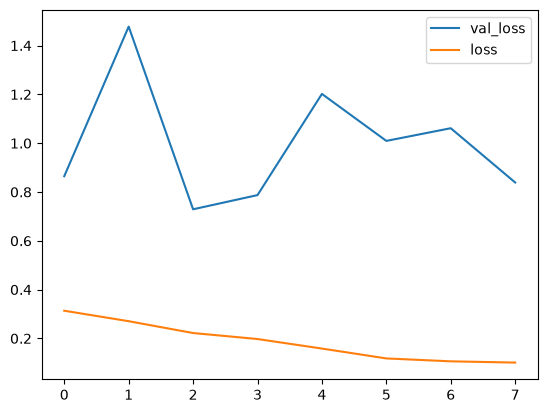

In [112]:
pd.DataFrame(mymodel.history.history)[['val_loss','loss']].plot()

<Axes: >

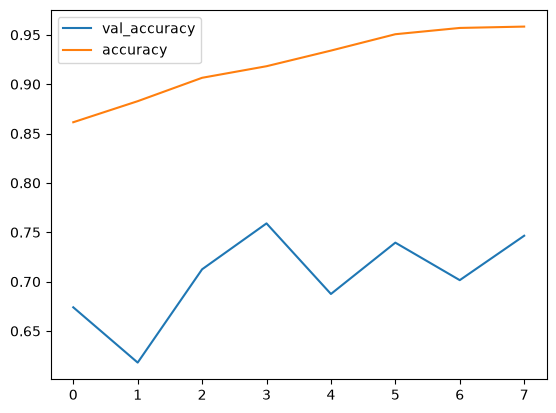

In [113]:
pd.DataFrame(mymodel.history.history)[['val_accuracy','accuracy']].plot()

In [114]:
#prediction = mymodel.predict_generator(validation_data_set)

In [115]:
prediction = mymodel.predict(validation_data_set)   

20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 84ms/step


In [116]:
prediction

array([[1.6216080e-03],
       [8.6805206e-03],
       [3.9286618e-03],
       ...,
       [1.5215990e-04],
       [5.4644173e-01],
       [9.9994618e-01]], shape=(2000, 1), dtype=float32)

In [117]:
prediction = prediction>0.5

In [118]:
validation_data_set.classes

array([0, 0, 0, ..., 1, 1, 1], shape=(2000,), dtype=int32)

In [119]:
(validation_data_set.classes, prediction)

(array([0, 0, 0, ..., 1, 1, 1], shape=(2000,), dtype=int32),
 array([[False],
        [False],
        [False],
        ...,
        [False],
        [ True],
        [ True]], shape=(2000, 1)))

In [120]:
from sklearn.metrics import classification_report, confusion_matrix

In [121]:
print(classification_report(validation_data_set.classes, prediction))

              precision    recall  f1-score   support

           0       0.71      0.84      0.77      1000
           1       0.80      0.66      0.72      1000

    accuracy                           0.75      2000
   macro avg       0.76      0.75      0.74      2000
weighted avg       0.76      0.75      0.74      2000



In [122]:
confused = confusion_matrix(validation_data_set.classes, prediction)
confused

array([[836, 164],
       [342, 658]])

<Axes: >

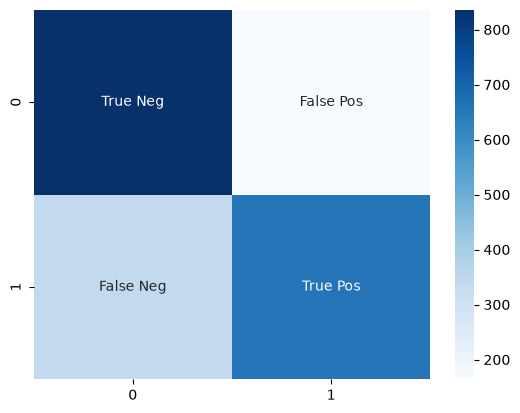

In [123]:
labels = ['True Neg','False Pos','False Neg','True Pos']
labels = np.asarray(labels).reshape(2,2)

sns.heatmap(confused, annot= labels, fmt='', cmap='Blues')

In [124]:
import pickle

with open('/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/classifier.pkl', 'wb') as file:
    pickle.dump(mymodel, file)

In [125]:
os.getcwd()

'/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/notebooks'

In [126]:
os.listdir()

['cnn_binary_image.ipynb', 'model.png', '.ipynb_checkpoints']

In [127]:
#%pip install --upgrade pyngrok

In [135]:
from flask import Flask, request, render_template, jsonify
import pickle
import pandas as pd
from flask_ngrok import run_with_ngrok
from sklearn.feature_extraction import DictVectorizer
from sklearn.preprocessing import StandardScaler
import pyngrok
import ngrok


from flask import Flask, request, render_template, send_from_directory
from pyngrok import ngrok
from tensorflow.keras.preprocessing.image import load_img, img_to_array



In [136]:
%%writefile /Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/templates/index.html

<!DOCTYPE html>
<html lang="en">

<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">

    <title>CNN Cat and Dog Classifier</title>

    <link rel="stylesheet"
          href="{{ url_for('static', filename='style.css') }}">
</head>

<body>

    <div class="container">

        <h1>🐱 Cat & Dog Classifier 🐶</h1>

        <p class="subtitle">
            Upload an image and let our CNN model classify it.
        </p>

        <form action="/predict"
              method="POST"
              enctype="multipart/form-data">

            <label for="image">Choose an image</label>

            <input
                type="file"
                id="image"
                name="image"
                accept=".jpg,.jpeg,.png"
                required
            >

            <button type="submit">
                Classify Image
            </button>

        </form>

        {% if prediction %}

        <div class="result">

            <h2>Prediction: {{ prediction }}</h2>

            {% if prediction != "NOT RECOGNISED" %}
                <h3>Confidence: {{ confidence }}%</h3>
            {% else %}
                <p class="warning">
                    Sorry, I could not recognise this image as a cat or dog.
                </p>
            {% endif %}

            <img
                src="{{ url_for('uploaded_file', filename=image_name) }}"
                alt="Uploaded image"
            >

        </div>

        {% endif %}

    </div>

</body>
</html>

Overwriting /Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/templates/index.html


In [139]:
%%writefile /Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/static/style.css

body {
    font-family: Arial, sans-serif;
    background: linear-gradient(135deg, #dbeafe, #f0f9ff);
    text-align: center;
    margin: 0;
    padding: 50px 20px;
}

.container {
    background: white;
    max-width: 650px;
    margin: auto;
    padding: 40px;
    border-radius: 18px;
    box-shadow: 0 8px 25px rgba(0, 0, 0, 0.12);
}

h1 {
    color: #1e3a8a;
    font-size: 30px;
}

.subtitle {
    color: #64748b;
    font-size: 16px;
    margin-bottom: 30px;
}

label {
    display: block;
    font-weight: bold;
    color: #334155;
    margin-bottom: 12px;
}

input[type="file"] {
    display: block;
    margin: 15px auto 25px;
    padding: 12px;
    border: 1px solid #cbd5e1;
    border-radius: 8px;
    width: 85%;
}

button {
    background: #2563eb;
    color: white;
    border: none;
    padding: 14px 30px;
    border-radius: 8px;
    font-size: 16px;
    cursor: pointer;
}

button:hover {
    background: #1d4ed8;
}

.result {
    margin-top: 35px;
    padding: 25px;
    background: #eff6ff;
    border-radius: 12px;
}

.result h2 {
    color: #1e40af;
}

.result h3 {
    color: #334155;
}

.result img {
    max-width: 100%;
    max-height: 350px;
    border-radius: 12px;
    margin-top: 15px;
}

.warning {
    color: #dc2626;
    font-weight: bold;
}

Overwriting /Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/static/style.css


In [140]:
for path in [
    'app.py',
    'classifier.pkl',
    'templates/index.html',
    'static/style.css'
]:
    full_path = os.path.join(BASE_DIR, path)
    print(path, "✓ Found" if os.path.exists(full_path) else "✗ Missing")

app.py ✓ Found
classifier.pkl ✓ Found
templates/index.html ✓ Found
static/style.css ✓ Found


In [141]:
import os
import uuid
import pickle
import numpy as np

from flask import Flask, request, render_template, send_from_directory
from pyngrok import ngrok
from tensorflow.keras.preprocessing.image import load_img, img_to_array


#flask application
BASE_DIR = '/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification'

app = Flask(
    __name__,
    template_folder=os.path.join(BASE_DIR, 'templates')
)


#ngrok authentication

# Start ngrok
ngrok.kill()

tunnel = ngrok.connect(5000)

public_url = tunnel.public_url

print("Public URL:", public_url)

#loading CNN model
model_path = os.path.join(BASE_DIR, 'classifier.pkl')

with open(model_path, 'rb') as file:
    model = pickle.load(file)


#upload folder
UPLOAD_FOLDER = os.path.join(BASE_DIR, 'user')
os.makedirs(UPLOAD_FOLDER, exist_ok=True)


#home page
@app.route('/')
def home():
    return render_template('index.html')


#image prediction
@app.route('/predict', methods=['POST'])
def predict():

    try:
        if 'image' not in request.files:
            return "Please upload an image."

        file = request.files['image']

        if file.filename == '':
            return "Please select an image."

        allowed_extensions = {'jpg', 'jpeg', 'png'}

        if '.' not in file.filename:
            return "Invalid image file."

        extension = file.filename.rsplit('.', 1)[1].lower()

        if extension not in allowed_extensions:
            return "Please upload a JPG, JPEG or PNG image."

        #saving uploaded image
        filename = f"{uuid.uuid4().hex}.{extension}"
        image_path = os.path.join(UPLOAD_FOLDER, filename)

        file.save(image_path)

        #loading and resizing image
        image = load_img(
            image_path,
            target_size=(100, 100),
            color_mode='rgb'
        )

        image_array = img_to_array(image)
        image_array = np.expand_dims(image_array, axis=0)
        image_array = image_array / 255.0

        #model prediction
        prediction = model.predict(image_array, verbose=0)
        probability = float(prediction[0][0])

        #classifying image
        if probability >= 0.5:
            result = "DOG"
            confidence = probability * 100
        else:
            result = "CAT"
            confidence = (1 - probability) * 100

        #confidence threshold
        if confidence < 75:
            result = "NOT RECOGNISED"
            confidence = 0

        return render_template(
            'index.html',
            prediction=result,
            confidence=round(confidence, 2),
            image_name=filename
        )

    except Exception as e:
        print("Prediction error:", e)
        return f"An error occurred: {e}"


#displaying the  uploaded image
@app.route('/user/<filename>')
def uploaded_file(filename):
    return send_from_directory(UPLOAD_FOLDER, filename)


#running Flask
if __name__ == '__main__':
    app.run(
        port=5000,
        debug=False,
        use_reloader=False
    )

Public URL: https://spry-hazy-fall.ngrok-free.dev
 * Serving Flask app '__main__'
 * Debug mode: off


 * Running on http://127.0.0.1:5000
Press CTRL+C to quit
127.0.0.1 - - [06/Nov/2026 00:16:31] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [06/Nov/2026 00:16:31] "GET /static/style.css HTTP/1.1" 404 -
t=2026-11-06T00:16:42+0000 lvl=warn msg="Stopping forwarder" name=http-5000-2e00c1fa-dbd7-434a-a159-0bb41b9f12bd acceptErr="failed to accept connection: Listener closed"
